In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set text. Requires a LaTeX installation for usetex=True.
plt.rcParams.update(
    {
        'text.usetex': True,
        'font.family': 'serif',
        'font.serif': ['Computer Modern Roman'],
        'font.size': 13,
        'axes.linewidth': 0.8,
        'savefig.bbox': 'tight',
    }
)


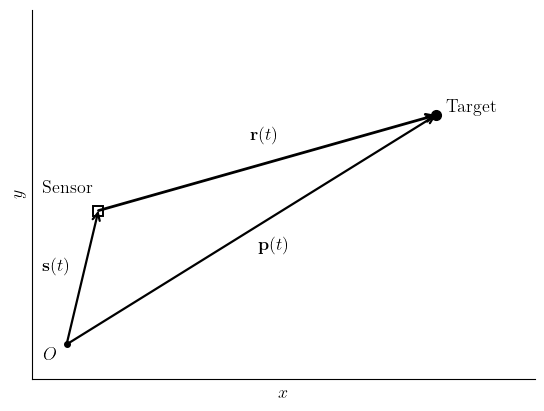

In [9]:
s = np.array([0.5, 2.1])
p = np.array([5.8, 3.6])
r = p - s
fig, ax = plt.subplots(figsize=(7, 4.8))


def arrow(start, delta, label, offset=(0, 0), lw=1.6):
    ax.annotate(
        '',
        xy=start + delta,
        xytext=start,
        arrowprops={
            'arrowstyle': '->',
            'color': 'black',
            'lw': lw,
            'shrinkA': 0,
            'shrinkB': 0,
            'mutation_scale': 13,
        },
    )
    middle = start + 0.5 * delta + np.array(offset)
    ax.text(*middle, label, ha='center', va='center')


origin = np.zeros(2)
arrow(origin, s, r'$\mathbf{s}(t)$', (-0.42, 0.16))
arrow(origin, p, r'$\mathbf{p}(t)$', (0.35, -0.25))
arrow(s, r, r'$\mathbf{r}(t)$', (-0.05, 0.43), lw=2.0)

ax.plot(*origin, 'ko', ms=4)
ax.plot(*s, 'ks', ms=7, mfc='white', mew=1.4)
ax.plot(*p, 'ko', ms=7)
ax.text(-0.16, -0.24, r'$O$', ha='right')
ax.text(s[0] - 0.1, s[1] + 0.28, 'Sensor', ha='right')
ax.text(p[0] + 0.16, p[1] + 0.04, 'Target', ha='left')

ax.set(xlim=(-0.55, 7.35), ylim=(-0.55, 5.25), xlabel=r'$x$', ylabel=r'$y$')
ax.set_aspect('equal', adjustable='box')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
fig.savefig('./figures/tma_relative_position.png', dpi=220)
plt.show()
plt.close(fig)

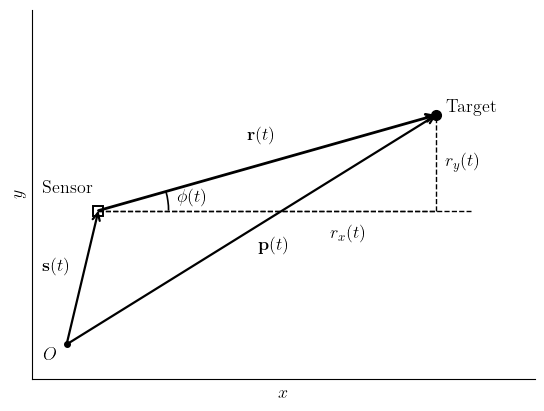

In [ ]:
from matplotlib.patches import Arc

# Assumes your rcParams already enable:
# plt.rcParams['text.usetex'] = True
# plt.rcParams['font.family'] = 'serif'

s = np.array([0.5, 2.1])
p = np.array([5.8, 3.6])
r = p - s
phi = np.arctan2(r[1], r[0])

fig, ax = plt.subplots(figsize=(7, 4.8))


def arrow(start, delta, label, offset=(0, 0), lw=1.6):
    ax.annotate(
        '',
        xy=start + delta,
        xytext=start,
        arrowprops={
            'arrowstyle': '->',
            'color': 'black',
            'lw': lw,
            'shrinkA': 0,
            'shrinkB': 0,
            'mutation_scale': 13,
        },
    )
    middle = start + 0.5 * delta + np.array(offset)
    ax.text(*middle, label, ha='center', va='center')


origin = np.zeros(2)

# Main vectors
arrow(origin, s, r'$\mathbf{s}(t)$', (-0.42, 0.16))
arrow(origin, p, r'$\mathbf{p}(t)$', (0.35, -0.25))
arrow(s, r, r'$\mathbf{r}(t)$', (-0.10, 0.43), lw=2.0)

# Points
ax.plot(*origin, 'ko', ms=4)
ax.plot(*s, 'ks', ms=7, mfc='white', mew=1.4)
ax.plot(*p, 'ko', ms=7)

# Labels
ax.text(-0.16, -0.24, r'$O$', ha='right')
ax.text(s[0] - 0.1, s[1] + 0.28, 'Sensor', ha='right')
ax.text(p[0] + 0.16, p[1] + 0.04, 'Target', ha='left')

# Dashed horizontal reference ray from the sensor
x_ref_end = p[0] + 0.55
ax.plot([s[0], x_ref_end], [s[1], s[1]], 'k--', lw=1.0)

# Dashed projection lines showing r_x and r_y
proj = np.array([p[0], s[1]])
ax.plot([s[0], proj[0]], [s[1], proj[1]], 'k--', lw=1.0)
ax.plot([proj[0], p[0]], [proj[1], p[1]], 'k--', lw=1.0)

# Optional labels for components
ax.text(
    0.7 * (s[0] + proj[0]), s[1] - 0.22, r'$r_x(t)$', ha='center', va='top'
)
ax.text(
    p[0] + 0.14, 0.5 * (proj[1] + p[1]), r'$r_y(t)$', ha='left', va='center'
)

# Angle arc for phi(t)
arc_radius = 1.1
arc = Arc(
    s,
    width=2 * arc_radius,
    height=2 * arc_radius,
    angle=0,
    theta1=0,
    theta2=np.degrees(phi),
    lw=1.2,
    color='black',
)
ax.add_patch(arc)

# Label for phi(t)
phi_label_radius = 1.35
phi_label_pos = s + phi_label_radius * np.array(
    [1.1 * np.cos(phi / 2), 1.1 * np.sin(phi / 2)]
)
ax.text(
    phi_label_pos[0], phi_label_pos[1], r'$\phi(t)$', ha='center', va='center'
)

# Axes styling
ax.set(xlim=(-0.55, 7.35), ylim=(-0.55, 5.25), xlabel=r'$x$', ylabel=r'$y$')
ax.set_aspect('equal', adjustable='box')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

fig.savefig('./figures/tma_azimuth_geometry.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)